In [1]:
import random
import time
import matplotlib.pyplot as plt
from IPython.display import clear_output
from matplotlib.patches import Rectangle


class Passenger:
    def __init__(self, pid, row, seat, luggage_delay=None):
        self.pid = pid # Unique passenger ID number (e.g., 1, 2, 3...)
        self.row = row # The target row where the passenger will sit (Row 1–9 on our simulate model)
        self.seat = seat # The seat column name assigned to the passenger (A, B, C, D, E, or F)
        self.x = -1 # Current x-position in the aisle, we set x=-1 to indicate that a passenger has not entered yet
        self.y = None # Current y-position (column index), which will be set when the passenger enters the plane.
        self.seated = False # Will be used to define whether a passenger is already seated (either True or False)
        self.luggage_delay = random.randint(9, 12) # Set number of steps needed to place luggage in the overhead bin. At least 9 seconds and at most 12 seconds to place 1 luggage
        self.remaining_delay = self.luggage_delay # Remaining luggage time in seconds (counts down as simulation runs)

    def __repr__(self):
        return f"Passenger(row={self.row}, seat={self.seat}, seated={self.seated})" #learned from cell class in HW02

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch #from HW02 show function
import time #from HW02 
from IPython.display import clear_output #from HW02 
import random

class Plane:
    def __init__(self, num_rows):
        self.num_rows = num_rows
        self.seat_letters = ["A", "B", "C", "D", "E", "F"]
        self.aisle_y = 3
        self.entrance_y = 3

        # plane state
        self.passengers = []

        # seat map
        self.seats = {}
        for row in range(1, num_rows + 1):
            for seat in self.seat_letters:
                self.seats[(row, seat)] = None

    # seat letter indicates y coordinate
    def get_seat_y(self, seat):
        return {"A": 0, "B": 1, "C": 2, "D": 4, "E": 5, "F": 6}[seat]

    # add passenger to queue
    def add_passenger(self, passenger):
        passenger.x = -1
        passenger.y = self.entrance_y
        self.passengers.append(passenger)

    # sit a passenger (fill seat)
    def sit_passenger(self, passenger):
        if self.seats[(passenger.row, passenger.seat)] is None:
            self.seats[(passenger.row, passenger.seat)] = passenger
            passenger.seated = True
            return True
        return False

    # Updated step() funtion which avoid queuing conflict
    def step(self):

        intentions = {}

        # order of movement follows queue order
        order = {p: i for i, p in enumerate(self.passengers)}

        # cells currently occupied (only aisle movers, not seated ones)
        occupied = {(p.x, p.y) for p in self.passengers
                    if (not p.seated and p.x >= 0)}

        movers = [p for p in self.passengers if not p.seated]

        for p in movers:

            # Stage 1. entering plane
            if p.x < 0:
                target = (0, self.aisle_y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 2. walk forward in aisle until (row-1, aisle)
            if p.x < p.row - 1:
                nx = p.x + 1
                target = (nx, p.y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 3. step sideways toward seat
            seat_y = self.get_seat_y(p.seat)

            if p.y < seat_y:
                target = (p.x, p.y + 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            if p.y > seat_y:
                target = (p.x, p.y - 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 4. luggage delay
            if p.remaining_delay > 0:
                p.remaining_delay -= 1
                intentions[p] = (p.x, p.y)
                continue

            # Stage 5. sit down
            self.sit_passenger(p)
            intentions[p] = (p.x, p.y)

        cell_to_list = {}
        for p, cell in intentions.items():
            cell_to_list.setdefault(cell, []).append(p)

        # apply moves
        for cell, plist in cell_to_list.items():
            if len(plist) == 1:
                p = plist[0]
                if not p.seated:
                    p.x, p.y = cell
            else:
                # choose winner by queue order
                winner = min(plist, key=lambda x: order[x])
                if not winner.seated:
                    winner.x, winner.y = cell
                # losers remain

    # animate run() with plot
    def run(self):
        start = time.time()
        step_count = 0
        while not all(p.seated for p in self.passengers):
            clear_output(wait=True)
            self.show()
            self.step()
            step_count += 1
            time.sleep(0.1)

        clear_output(wait=True)
        self.show()
        end = time.time()
        print(f"It took {round(end - start, 2)} seconds")

    # fast mode: Run simulation without plotting, accumulating REAL boarding time.
    # Each step represents `seconds_per_step` real seconds.
    def run_no_plot(self, seconds_per_step=0.5):
        total_time = 0.0

        while not all(p.seated for p in self.passengers):
            self.step()
            total_time += seconds_per_step

        return total_time

    # visualization (original)
    def show(self):
        for (row, seat), passenger in self.seats.items():
            y = self.get_seat_y(seat)
            color = "green" if passenger else "white"
            plt.scatter(row - 1, y, s=500, c=color, edgecolors='black')

        for p in self.passengers:
            if not p.seated:
                plt.scatter(p.x, p.y, s=500, c='red', edgecolors='black')

        plt.grid()
        plt.xticks(range(self.num_rows))
        plt.yticks(range(7))
        plt.xlim(-1, self.num_rows)
        plt.ylim(-1, 7)
        plt.show()

## Do a small check to see if it works or not

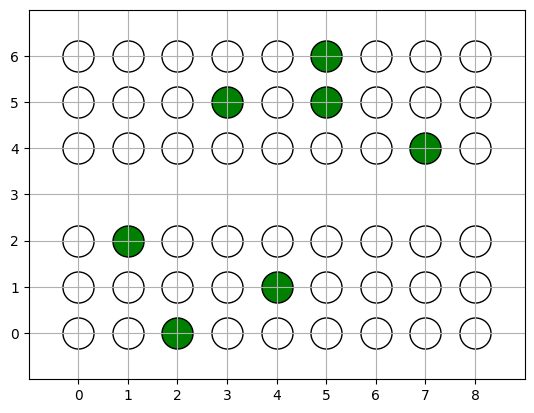

It took 16.91 seconds


In [3]:
boeing = Plane(num_rows=9)

passengers = [
    Passenger(1, 3, "A"),
    Passenger(2, 4, "E"),
    Passenger(3, 2, "C"),
    Passenger(4, 5, "B"),
    Passenger(5, 6, "F"),
    Passenger(6, 8, "D"),
    Passenger(7, 6, "E")
]

# Add passengers to the plane
for p in passengers:
    boeing.add_passenger(p)

# Run the simulation
boeing.run()

## Firstly, we are wondering if letting passengers take seats from front to back and from window to aisle will make boarding efficiently

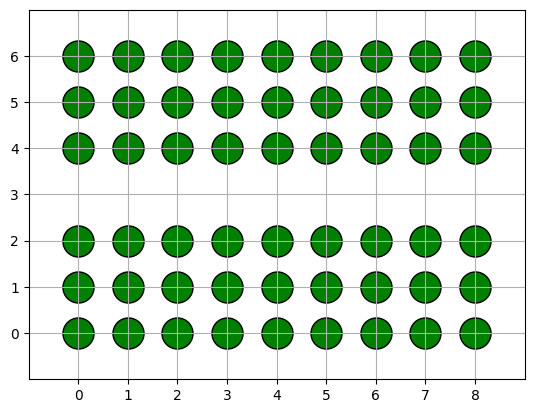

It took 144.61 seconds


In [4]:
full_boeing = Plane(num_rows=9)

ordered_full_passengers = [
    Passenger(1, 1, "A"),
    Passenger(2, 1, "B"),
    Passenger(3, 1, "C"),
    Passenger(4, 1, "D"),
    Passenger(5, 1, "E"),
    Passenger(6, 1, "F"),

    Passenger(7, 2, "A"),
    Passenger(8, 2, "B"),
    Passenger(9, 2, "C"),
    Passenger(10, 2, "D"),
    Passenger(11, 2, "E"),
    Passenger(12, 2, "F"),

    Passenger(13, 3, "A"),
    Passenger(14, 3, "B"),
    Passenger(15, 3, "C"),
    Passenger(16, 3, "D"),
    Passenger(17, 3, "E"),
    Passenger(18, 3, "F"),

    Passenger(19, 4, "A"),
    Passenger(20, 4, "B"),
    Passenger(21, 4, "C"),
    Passenger(22, 4, "D"),
    Passenger(23, 4, "E"),
    Passenger(24, 4, "F"),

    Passenger(25, 5, "A"),
    Passenger(26, 5, "B"),
    Passenger(27, 5, "C"),
    Passenger(28, 5, "D"),
    Passenger(29, 5, "E"),
    Passenger(30, 5, "F"),

    Passenger(31, 6, "A"),
    Passenger(32, 6, "B"),
    Passenger(33, 6, "C"),
    Passenger(34, 6, "D"),
    Passenger(35, 6, "E"),
    Passenger(36, 6, "F"),

    Passenger(37, 7, "A"),
    Passenger(38, 7, "B"),
    Passenger(39, 7, "C"),
    Passenger(40, 7, "D"),
    Passenger(41, 7, "E"),
    Passenger(42, 7, "F"),

    Passenger(43, 8, "A"),
    Passenger(44, 8, "B"),
    Passenger(45, 8, "C"),
    Passenger(46, 8, "D"),
    Passenger(47, 8, "E"),
    Passenger(48, 8, "F"),

    Passenger(49, 9, "A"),
    Passenger(50, 9, "B"),
    Passenger(51, 9, "C"),
    Passenger(52, 9, "D"),
    Passenger(53, 9, "E"),
    Passenger(54, 9, "F")
]


# Add passengers to the plane
for p in ordered_full_passengers:
    full_boeing.add_passenger(p)

# Run the simulation
full_boeing.run()

## In this case, we will do it reversely, which let passengers take seats from back to front and from window to aisle

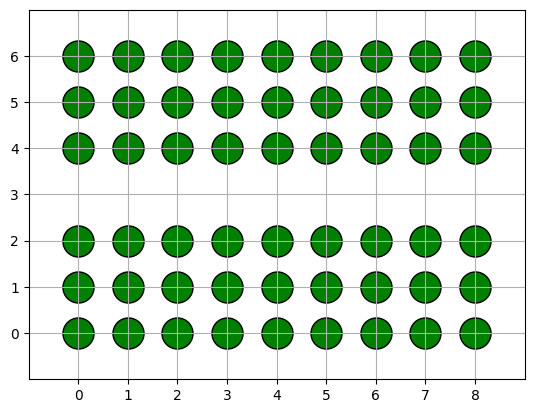

It took 143.87 seconds


In [5]:
full_reverse_order_boeing = Plane(num_rows=9)

reverse_full_passengers = [
    Passenger(54, 9, "F"),
    Passenger(53, 9, "E"),
    Passenger(52, 9, "D"),
    Passenger(51, 9, "C"),
    Passenger(50, 9, "B"),
    Passenger(49, 9, "A"),

    Passenger(48, 8, "F"),
    Passenger(47, 8, "E"),
    Passenger(46, 8, "D"),
    Passenger(45, 8, "C"),
    Passenger(44, 8, "B"),
    Passenger(43, 8, "A"),

    Passenger(42, 7, "F"),
    Passenger(41, 7, "E"),
    Passenger(40, 7, "D"),
    Passenger(39, 7, "C"),
    Passenger(38, 7, "B"),
    Passenger(37, 7, "A"),

    Passenger(36, 6, "F"),
    Passenger(35, 6, "E"),
    Passenger(34, 6, "D"),
    Passenger(33, 6, "C"),
    Passenger(32, 6, "B"),
    Passenger(31, 6, "A"),

    Passenger(30, 5, "F"),
    Passenger(29, 5, "E"),
    Passenger(28, 5, "D"),
    Passenger(27, 5, "C"),
    Passenger(26, 5, "B"),
    Passenger(25, 5, "A"),

    Passenger(24, 4, "F"),
    Passenger(23, 4, "E"),
    Passenger(22, 4, "D"),
    Passenger(21, 4, "C"),
    Passenger(20, 4, "B"),
    Passenger(19, 4, "A"),

    Passenger(18, 3, "F"),
    Passenger(17, 3, "E"),
    Passenger(16, 3, "D"),
    Passenger(15, 3, "C"),
    Passenger(14, 3, "B"),
    Passenger(13, 3, "A"),

    Passenger(12, 2, "F"),
    Passenger(11, 2, "E"),
    Passenger(10, 2, "D"),
    Passenger(9, 2, "C"),
    Passenger(8, 2, "B"),
    Passenger(7, 2, "A"),

    Passenger(6, 1, "F"),
    Passenger(5, 1, "E"),
    Passenger(4, 1, "D"),
    Passenger(3, 1, "C"),
    Passenger(2, 1, "B"),
    Passenger(1, 1, "A")
]



# Add passengers to the plane
for p in reverse_full_passengers:
    full_reverse_order_boeing.add_passenger(p)

# Run the simulation
full_reverse_order_boeing.run()

## As we can see from above, boarding passengers from back to front and from window to aisle is more efficient.

## According to the website cited below, we are interested in whether wilma method would be faster than that which boards passengers from back to front and from window to aisle.

### Reference: https://boardingarea.com/all-about-uniteds-new-wilma-boarding-for-frequent-flyers/

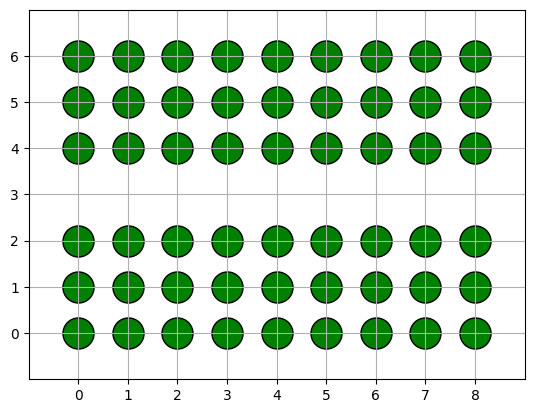

It took 76.37 seconds


In [6]:
#Window-Middle-Aisle Boarding method

for p in passengers:
    boeing.add_passenger(p)
    
wilma_boeing = Plane(num_rows=9)

# Full list of passengers 
wilma_passengers = [
    Passenger(1, 1, "A"),
    Passenger(2, 1, "B"),
    Passenger(3, 1, "C"),
    Passenger(4, 1, "D"),
    Passenger(5, 1, "E"),
    Passenger(6, 1, "F"),

    Passenger(7, 2, "A"),
    Passenger(8, 2, "B"),
    Passenger(9, 2, "C"),
    Passenger(10, 2, "D"),
    Passenger(11, 2, "E"),
    Passenger(12, 2, "F"),

    Passenger(13, 3, "A"),
    Passenger(14, 3, "B"),
    Passenger(15, 3, "C"),
    Passenger(16, 3, "D"),
    Passenger(17, 3, "E"),
    Passenger(18, 3, "F"),

    Passenger(19, 4, "A"),
    Passenger(20, 4, "B"),
    Passenger(21, 4, "C"),
    Passenger(22, 4, "D"),
    Passenger(23, 4, "E"),
    Passenger(24, 4, "F"),

    Passenger(25, 5, "A"),
    Passenger(26, 5, "B"),
    Passenger(27, 5, "C"),
    Passenger(28, 5, "D"),
    Passenger(29, 5, "E"),
    Passenger(30, 5, "F"),

    Passenger(31, 6, "A"),
    Passenger(32, 6, "B"),
    Passenger(33, 6, "C"),
    Passenger(34, 6, "D"),
    Passenger(35, 6, "E"),
    Passenger(36, 6, "F"),

    Passenger(37, 7, "A"),
    Passenger(38, 7, "B"),
    Passenger(39, 7, "C"),
    Passenger(40, 7, "D"),
    Passenger(41, 7, "E"),
    Passenger(42, 7, "F"),

    Passenger(43, 8, "A"),
    Passenger(44, 8, "B"),
    Passenger(45, 8, "C"),
    Passenger(46, 8, "D"),
    Passenger(47, 8, "E"),
    Passenger(48, 8, "F"),

    Passenger(49, 9, "A"),
    Passenger(50, 9, "B"),
    Passenger(51, 9, "C"),
    Passenger(52, 9, "D"),
    Passenger(53, 9, "E"),
    Passenger(54, 9, "F")
]

window_seats = ["A", "F"]
middle_seats = ["B", "E"]
aisle_seats = ["C", "D"]

#AI-generated function for segregating passengers into rows
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 19, 2025
#Prompt: "Explain how to use a key to choose passenger seating order"

wilma_sorted = sorted(
    wilma_passengers,
    key=lambda p: (
        # Assign a group number based on seat type:
        # 0 = window, 1 = middle, 2 = aisle
        0 if p.seat in window_seats else
        1 if p.seat in middle_seats else
        2,

        # Sort rows in reverse order (back to front)
        # Using negative row number achieves descending order
        -p.row
    )
)

for p in wilma_sorted:
    wilma_boeing.add_passenger(p)

# Run simulation
wilma_boeing.run()

### Great Found! We found that wilma boading is the way faster than the method we thought.

## However, there are two more methods suggested by the website cited below, which are Southwest method and Steffen method.

## https://www.vox.com/2014/4/25/5647696/the-way-we-board-airplanes-makes-absolutely-no-sense

## Let's try Southwest Method first!

In [17]:
def southwest_assign_seats(_passengers=None):
    """
    Southwest open seating:
    Create 54 passengers and randomly assign them
    one of the 54 seats on the plane (1A–9F).
    """

    seats = [(row, seat)
             for row in range(1, 10)
             for seat in ["A", "B", "C", "D", "E", "F"]]

    random.shuffle(seats)

    passengers = []
    for pid, (row, seat) in enumerate(seats, start=1):
        passengers.append(Passenger(pid, row, seat))

    return passengers

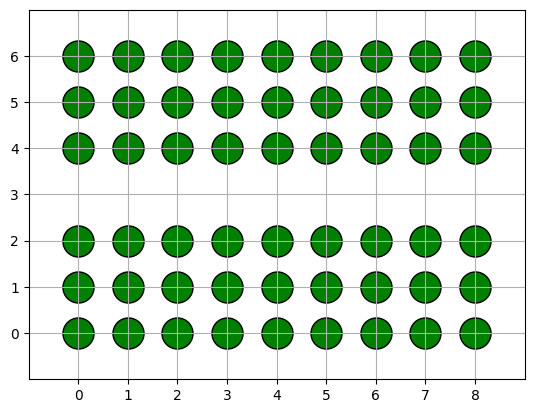

It took 94.39 seconds


In [18]:
sw_passengers = southwest_assign_seats()

sw_boeing = Plane(num_rows=9)

for p in sw_passengers:
    sw_boeing.add_passenger(p)

sw_boeing.run()

In [9]:
#AI-assisted completion of the Steffen boarding method implementation
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Note: A portion of this method required clarification regarding the correct ordering logic 
#(seat-group priority and alternating-row structure), so assistance was used to refine and 
#complete the final implementation.
def make_passengers():
    passengers = []
    pid = 1
    for row in range(1, 10):  # rows 1 to 9
        for seat in ["A", "B", "C", "D", "E", "F"]:
            passengers.append(Passenger(pid, row, seat))
            pid += 1
    return passengers

def steffen_boarding(passengers):
    """
    Jason Steffen boarding method (optimized boarding):
    1) Prioritize seat groups in the order: Window (A/F) → Middle (B/E) → Aisle (C/D)
    2) Within each seat group, apply an 'alternating row' pattern:
          Odd-numbered rows first, Even-numbered rows will become the alternating row
    3) Both odd and even groups are sorted back-to-front (higher row → lower row) based on our experience
    """

    window = ["A", "F"]
    middle = ["B", "E"]
    aisle  = ["C", "D"]

    def steffen_sort(group):
        """
        Sort a seat-type group using Steffen's alternating-row logic:
        - Separate passengers into odd vs. even rows
        - Sort each list from back to front
        - Return odd rows first, then even rows
        """

        odd_rows  = [p for p in group if p.row % 2 == 1]
        even_rows = [p for p in group if p.row % 2 == 0]

        # Back-to-front sorting (descending row number)
        odd_rows.sort(key=lambda p: -p.row)
        even_rows.sort(key=lambda p: -p.row)

        return odd_rows + even_rows
    
    # Categorize passengers by seat type
    window_ps = [p for p in passengers if p.seat in window]
    middle_ps = [p for p in passengers if p.seat in middle]
    aisle_ps  = [p for p in passengers if p.seat in aisle]

    # Apply Steffen ordering for each seat category
    ordered = []
    ordered += steffen_sort(window_ps)
    ordered += steffen_sort(middle_ps)
    ordered += steffen_sort(aisle_ps)

    return ordered

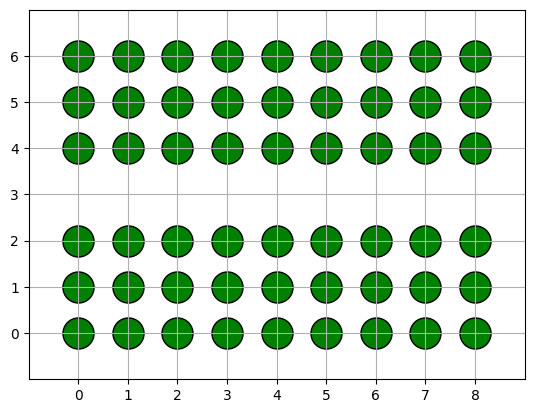

It took 77.9 seconds


In [10]:
plane = Plane(9)
for p in steffen_boarding(make_passengers()):
    plane.add_passenger(p)
plane.run()

## We found that there is not very much time difference between these two methods and wilma method. Thus, we would like to randomly run these methods 1000 times and calculate their mean time in second. 

In [11]:
#AI-generated code for applying multiple boarding strategies (similar to R's apply)
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Prompt: "I am writing a function which applies several plane boarding strategies using a list of 
# functions, runs each strategy 1000 times with random passengers. Could you please help me deal with the for loop so that it can compute the average 
# boarding time using measure_strategy(), and returns all results in a clean dictionary or table."


def measure_strategy(strategy_function, n=100, seconds_per_step=0.5):
    total = 0
    for i in range(n):
        passengers = make_passengers()
        plane = Plane(100)

        for p in strategy_function(passengers):
            plane.add_passenger(p)

        total += plane.run_no_plot(seconds_per_step=seconds_per_step)

    avg = total / n
    print(f"{strategy_function.__name__}: average = {avg:.2f} seconds over {n} runs")
    return avg

def make_passengers():
        passengers = []
        pid = 1
        for row in range(1, 10):  # From Row 1 to Row 9
            for seat in ["A", "B", "C", "D", "E", "F"]:
                passengers.append(Passenger(pid, row, seat))
                pid += 1
        return passengers

In [13]:
# This is a simple function which Window seats board first, followed by middle seats, and aisle seats last.
# Within each seat group, passengers board from back to front to minimize aisle congestion.
def wilma_boarding(passengers):
    window_seats = ["A", "F"]
    middle_seats = ["B", "E"]
    aisle_seats = ["C", "D"]

    # WILMA = Window, then Middle, then Aisle
    sorted_list = sorted(
        passengers,
        key=lambda p: (
            0 if p.seat in window_seats else
            1 if p.seat in middle_seats else
            2,
            -p.row
        )
    )
    return sorted_list

In [19]:
measure_strategy(wilma_boarding, n=1000)

wilma_boarding: average = 59.77 seconds over 1000 runs


59.768

In [20]:
measure_strategy(southwest_assign_seats, n=1000)

southwest_assign_seats: average = 68.76 seconds over 1000 runs


68.7625

In [21]:
measure_strategy(steffen_boarding, n=1000)

steffen_boarding: average = 60.28 seconds over 1000 runs


60.2835